# Task 4: Corporate Financial & Margin Performance Analysis
**Framework**: RISK (Requirements & Research, Investigation & Insight Discovery, Solution Engineering, Knowledge Delivery & KPI Validation)  
**Objective**: Comprehensive managerial accounting analysis across Gross Revenue, Concessions/Discounts, Net Sales, Cost of Goods Sold (COGS), Operating Margin, Segment Performance, and Parameterized What-If Scenarios.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

from src.data_cleaning import clean_financial
from src.metrics import (
    calculate_financial_kpis,
    aggregate_financial_by_dimension,
    generate_financial_waterfall_data,
    simulate_financial_scenario
)

print("Environment initialized successfully.")

Environment initialized successfully.


## 1. Accounting Data Ingestion & Reconciliation Check
We load the validated financial sample dataset where column header whitespace has been resolved, null discount bands standardized to `'No Discount'`, and accounting identities verified.

In [2]:
df_fin = clean_financial()
print(f"Financial Sample Dimensions: {df_fin.shape}")
print(f"Date Span: {df_fin['Date'].min().strftime('%Y-%m-%d')} to {df_fin['Date'].max().strftime('%Y-%m-%d')}")
print(f"Unique Countries: {df_fin['Country'].nunique()}, Unique Segments: {df_fin['Segment'].nunique()}, Products: {df_fin['Product'].nunique()}")

Financial Sample Dimensions: (700, 20)
Date Span: 2013-09-01 to 2014-12-01
Unique Countries: 5, Unique Segments: 5, Products: 6


## 2. High-Level Financial Statement & Ratio Analysis
Computing the verified corporate income statement hierarchy and managerial cost ratios.

In [3]:
kpis = calculate_financial_kpis(df_fin)

statement_df = pd.DataFrame([
    {"Statement Line": "1. Gross Sales Revenue", "Amount ($)": f"${kpis['gross_sales']:,.2f}", "% of Gross": "100.0%"},
    {"Statement Line": "2. Less: Commercial Discounts", "Amount ($)": f"(${kpis['total_discounts']:,.2f})", "% of Gross": f"{kpis['discount_impact_pct']:.2f}%"},
    {"Statement Line": "3. Net Realized Sales", "Amount ($)": f"${kpis['net_sales']:,.2f}", "% of Gross": f"{kpis['net_sales']/kpis['gross_sales']*100:.2f}%"},
    {"Statement Line": "4. Less: Cost of Goods Sold (COGS)", "Amount ($)": f"(${kpis['total_cogs']:,.2f})", "% of Gross": f"{kpis['total_cogs']/kpis['gross_sales']*100:.2f}%"},
    {"Statement Line": "5. Operating Contribution Profit", "Amount ($)": f"${kpis['total_profit']:,.2f}", "% of Gross": f"{kpis['total_profit']/kpis['gross_sales']*100:.2f}%"}
])
print(statement_df.to_string(index=False))

print(f"\n--- Operational Margins & Efficiency Ratios ---")
print(f"Gross Profit Margin (Profit / Net Sales): {kpis['gross_profit_margin_pct']:.2f}%")
print(f"COGS Absorption Ratio (COGS / Net Sales): {kpis['cogs_ratio_pct']:.2f}%")
print(f"Discount Concession Rate (Discounts / Gross Sales): {kpis['discount_impact_pct']:.2f}%")

                    Statement Line        Amount ($) % of Gross
            1. Gross Sales Revenue   $127,931,598.50     100.0%
     2. Less: Commercial Discounts   ($9,205,248.24)      7.20%
             3. Net Realized Sales   $118,726,350.25     92.80%
4. Less: Cost of Goods Sold (COGS) ($101,832,648.00)     79.60%
  5. Operating Contribution Profit    $16,893,702.25     13.21%

--- Operational Margins & Efficiency Ratios ---
Gross Profit Margin (Profit / Net Sales): 14.23%
COGS Absorption Ratio (COGS / Net Sales): 85.77%
Discount Concession Rate (Discounts / Gross Sales): 7.20%


## 3. Financial Bridge Waterfall: Gross Revenue to Net Profit
Visualizing the waterfall flow reconciling top-line gross revenue to bottom-line profit.

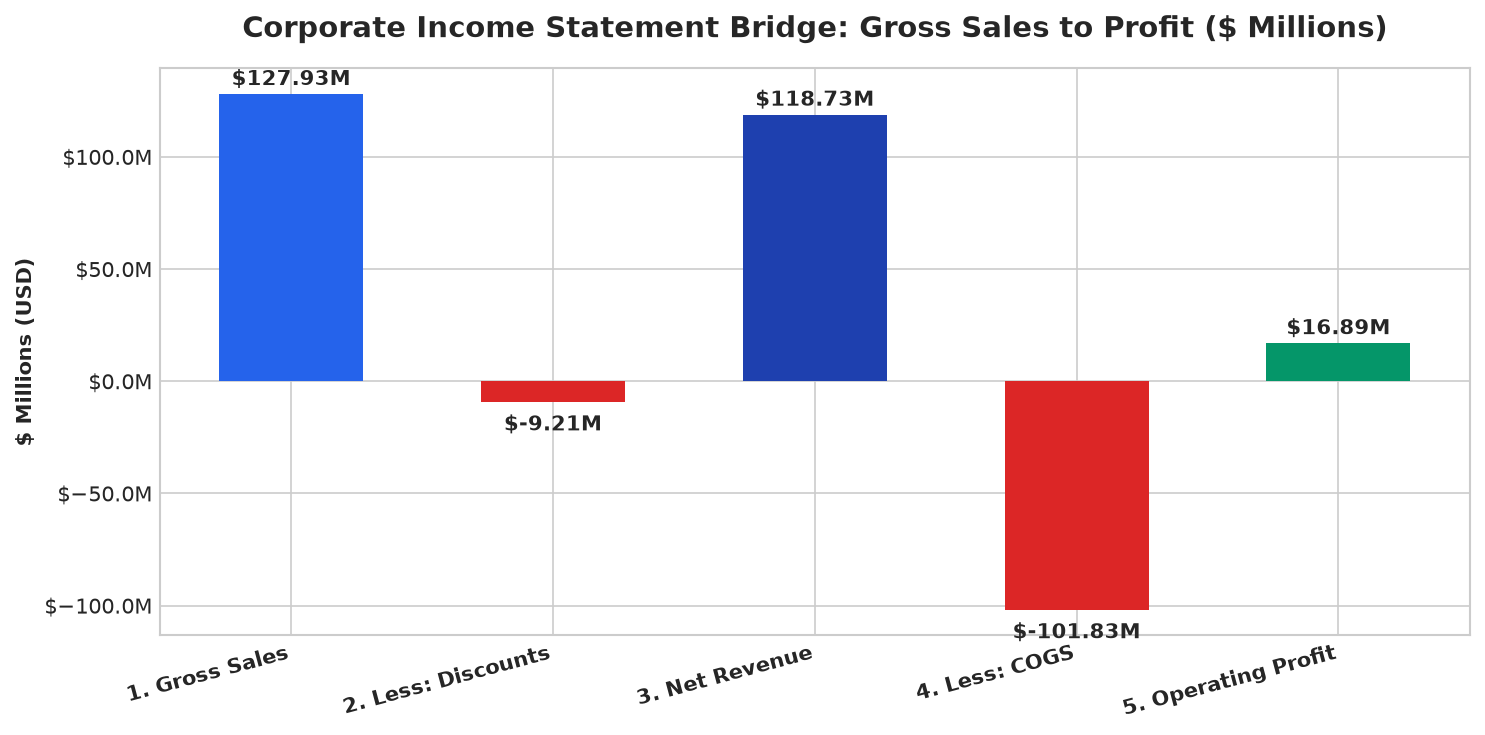

In [4]:
fig_dir = PROJECT_ROOT / "reports" / "figures" / "financial"
fig_dir.mkdir(parents=True, exist_ok=True)

waterfall_data = generate_financial_waterfall_data(df_fin)

fig, ax = plt.subplots(figsize=(10, 5))
steps = waterfall_data['Step']
amounts = waterfall_data['Amount'] / 1e6  # in Millions

colors = ['#2563EB', '#DC2626', '#1E40AF', '#DC2626', '#059669']
bars = ax.bar(steps, amounts, color=colors, width=0.55)

ax.set_title('Corporate Income Statement Bridge: Gross Sales to Profit ($ Millions)', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('$ Millions (USD)', fontweight='bold')
ax.yaxis.set_major_formatter('${x:,.1f}M')
plt.xticks(rotation=15, ha='right', fontsize=10, fontweight='bold')

for bar in bars:
    yval = bar.get_height()
    offset = 2 if yval >= 0 else -6
    ax.annotate(f"${yval:,.2f}M",
                xy=(bar.get_x() + bar.get_width() / 2, yval),
                xytext=(0, offset),
                textcoords="offset points",
                ha='center', va='bottom' if yval >= 0 else 'top',
                fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(fig_dir / "01_financial_income_waterfall.png", dpi=300)
plt.show()

## 4. Segment Margin Contribution & The Enterprise Loss Discovery
Evaluating profitability across Government, Small Business, Enterprise, Midmarket, and Channel Partners.

--- Segment Financial Performance Statement ---
         Segment  Units_Sold  Gross_Sales   Net_Sales       COGS      Profit  Gross_Profit_Margin_Pct  COGS_Ratio_Pct
      Government    470673.5   56403066.5 52504260.66 41116087.5 11388173.16                    21.69           78.31
  Small Business    153139.0   45941700.0 42427918.50 38284750.0  4143168.50                     9.77           90.23
      Enterprise    168552.0   21069000.0 19611694.38 20226240.0  -614545.62                    -3.13          103.13
       Midmarket    172178.0    2582670.0  2381883.07  1721780.0   660103.07                    27.71           72.29
Channel Partners    161263.5    1935162.0  1800593.64   483790.5  1316803.14                    73.13           26.87


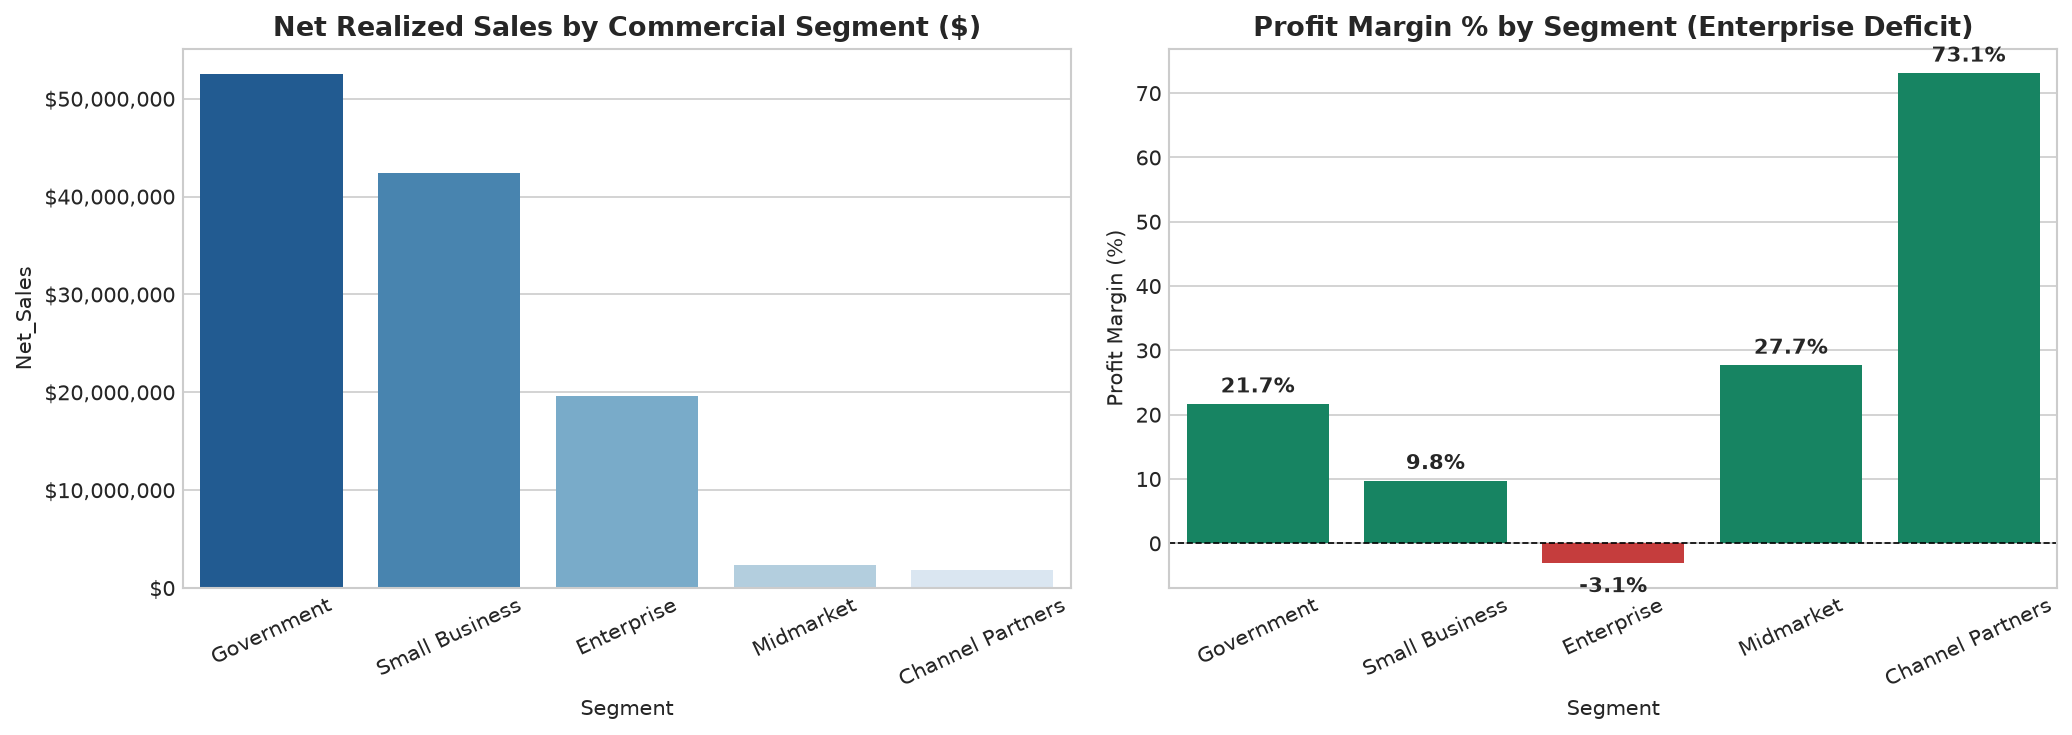

In [5]:
segment_fin = aggregate_financial_by_dimension(df_fin, 'Segment')
print("--- Segment Financial Performance Statement ---")
print(segment_fin[['Segment', 'Units_Sold', 'Gross_Sales', 'Net_Sales', 'COGS', 'Profit', 'Gross_Profit_Margin_Pct', 'COGS_Ratio_Pct']].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Net Sales by Segment
sns.barplot(data=segment_fin, x='Segment', y='Net_Sales', palette='Blues_r', ax=ax1, hue='Segment', legend=False)
ax1.set_title('Net Realized Sales by Commercial Segment ($)', fontweight='bold')
ax1.yaxis.set_major_formatter('${x:,.0f}')
ax1.tick_params(axis='x', rotation=25)

# Profit Margin % by Segment
colors = ['#059669' if m > 0 else '#DC2626' for m in segment_fin['Gross_Profit_Margin_Pct']]
sns.barplot(data=segment_fin, x='Segment', y='Gross_Profit_Margin_Pct', palette=colors, ax=ax2, hue='Segment', legend=False)
ax2.set_title('Profit Margin % by Segment (Enterprise Deficit)', fontweight='bold')
ax2.set_ylabel('Profit Margin (%)')
ax2.axhline(0, color='black', linestyle='--', linewidth=0.8)
ax2.tick_params(axis='x', rotation=25)

for p in ax2.patches:
    h = p.get_height()
    offset = 1 if h >= 0 else -2
    ax2.annotate(f"{h:.1f}%", (p.get_x() + p.get_width() / 2., h + offset),
                 ha='center', va='bottom' if h >= 0 else 'top', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(fig_dir / "02_segment_profit_and_cogs_ratio.png", dpi=300)
plt.show()

## 5. Sovereign Geographic Performance Analysis
Benchmarking Canada, Germany, France, Mexico, and the United States across net sales, COGS absorption, and operating margins.

--- Country Sovereign Performance ---
                 Country   Net_Sales       COGS     Profit  Gross_Profit_Margin_Pct  COGS_Ratio_Pct
United States of America 25029830.15 22034289.5 2995540.65                    11.97           88.03
                  Canada 24887654.88 21358426.0 3529228.88                    14.18           85.82
                  France 24354172.29 20573151.5 3781020.79                    15.53           84.47
                 Germany 23505340.82 19824952.0 3680388.82                    15.66           84.34
                  Mexico 20949352.11 18041829.0 2907523.11                    13.88           86.12


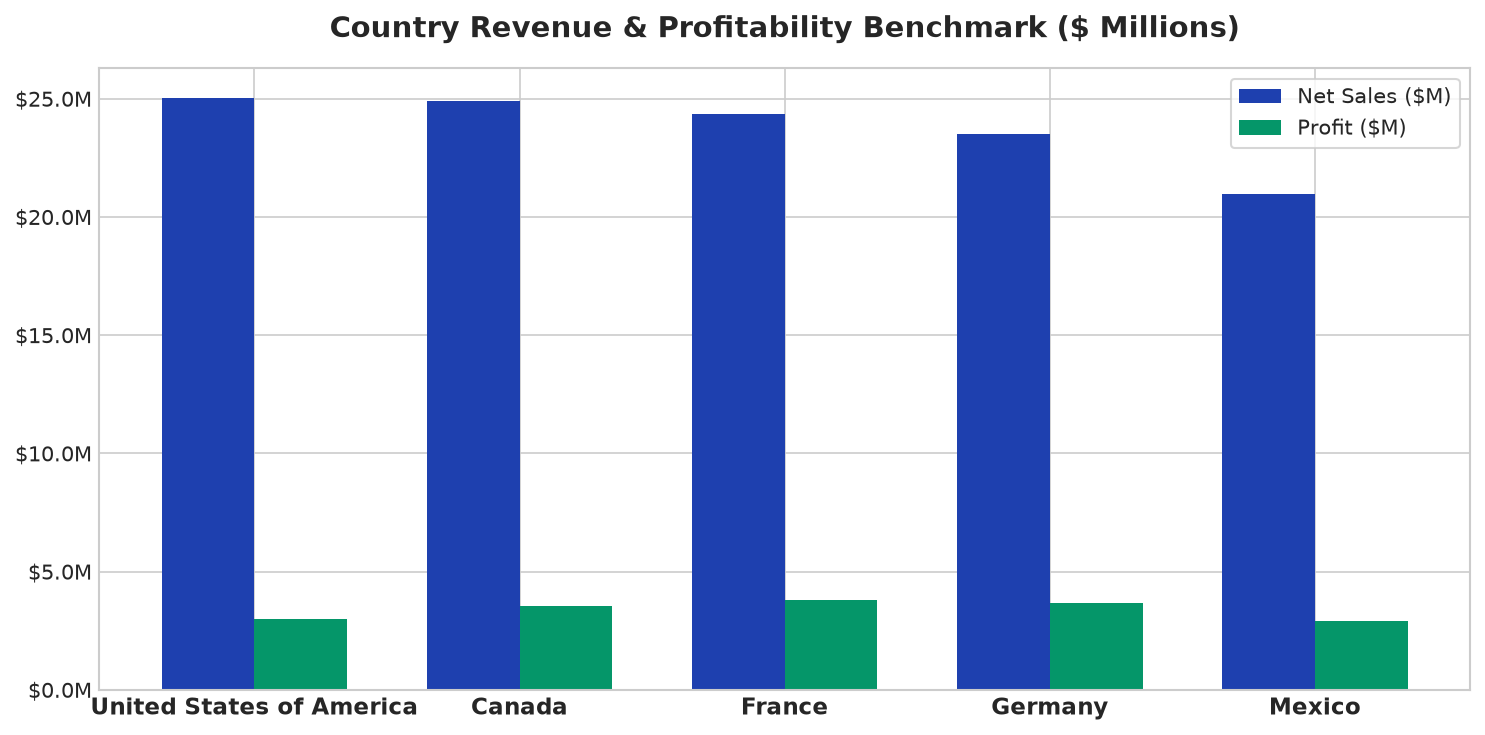

In [6]:
country_fin = aggregate_financial_by_dimension(df_fin, 'Country')
print("--- Country Sovereign Performance ---")
print(country_fin[['Country', 'Net_Sales', 'COGS', 'Profit', 'Gross_Profit_Margin_Pct', 'COGS_Ratio_Pct']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(country_fin))
width = 0.35

ax.bar(x - width/2, country_fin['Net_Sales']/1e6, width, label='Net Sales ($M)', color='#1E40AF')
ax.bar(x + width/2, country_fin['Profit']/1e6, width, label='Profit ($M)', color='#059669')

ax.set_title('Country Revenue & Profitability Benchmark ($ Millions)', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(country_fin['Country'], fontsize=11, fontweight='bold')
ax.yaxis.set_major_formatter('${x:,.1f}M')
ax.legend(frameon=True)

plt.tight_layout()
plt.savefig(fig_dir / "03_country_financial_performance.png", dpi=300)
plt.show()

## 6. Product Line Margin Breakdown
Evaluating commercial performance across the 6 core product lines: Paseo, Velo, VTT, Montana, Carretera, and Amarilla.

--- Product Line Performance ---
  Product   Net_Sales       COGS     Profit  Gross_Profit_Margin_Pct
    Paseo 33011143.94 28213706.0 4797437.94                    14.53
      VTT 20511921.02 17477313.0 3034608.02                    14.79
     Velo 18250059.47 15944067.0 2305992.47                    12.64
 Amarilla 17747116.05 14933012.0 2814104.05                    15.86
  Montana 15390801.88 13276047.0 2114754.88                    13.74
Carretera 13815307.89 11988503.0 1826804.89                    13.22


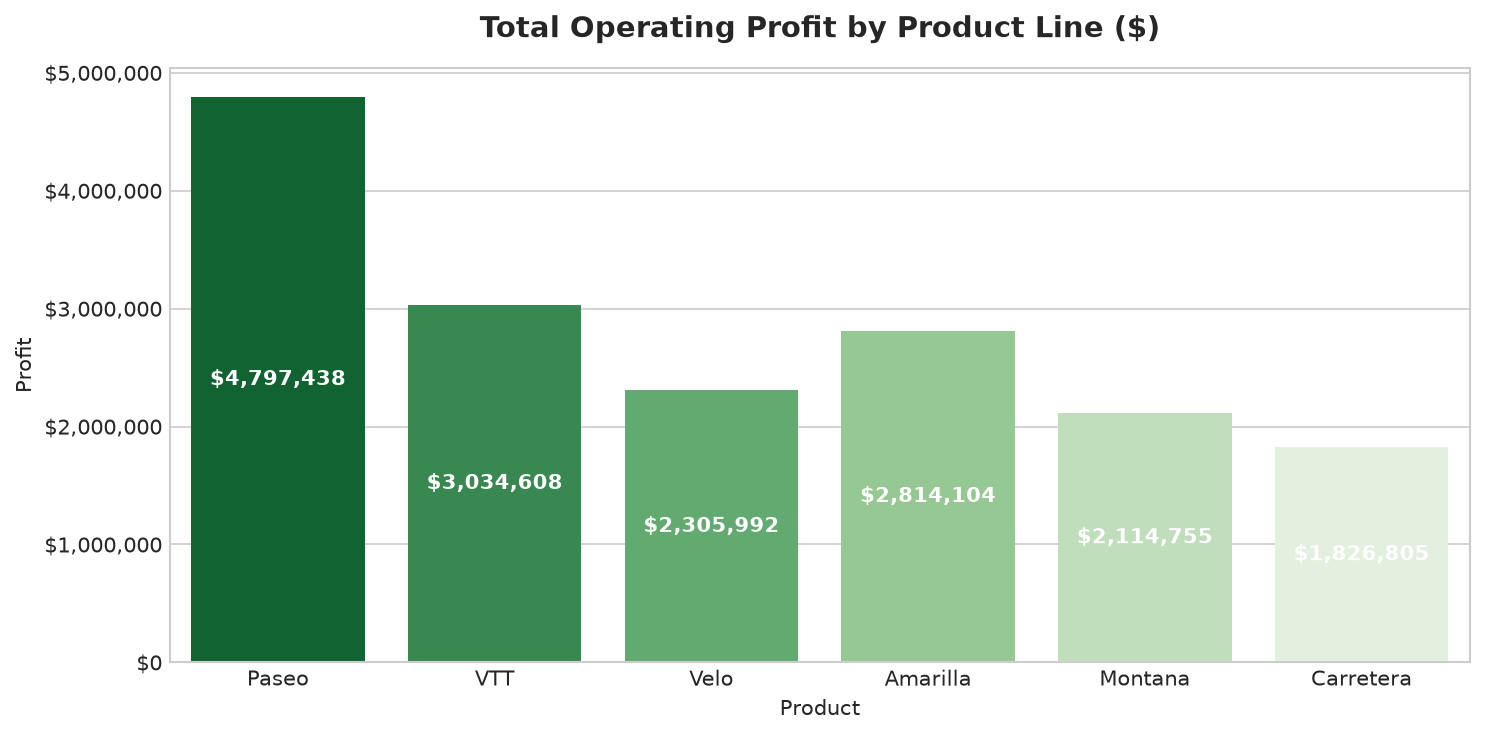

In [7]:
product_fin = aggregate_financial_by_dimension(df_fin, 'Product')
print("--- Product Line Performance ---")
print(product_fin[['Product', 'Net_Sales', 'COGS', 'Profit', 'Gross_Profit_Margin_Pct']].to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=product_fin, x='Product', y='Profit', palette='Greens_r', ax=ax, hue='Product', legend=False)
ax.set_title('Total Operating Profit by Product Line ($)', fontsize=14, fontweight='bold', pad=15)
ax.yaxis.set_major_formatter('${x:,.0f}')
for p in ax.patches:
    ax.annotate(f"${p.get_height():,.0f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                 ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(fig_dir / "04_product_line_profitability.png", dpi=300)
plt.show()

## 7. What-If Scenario & Margin Sensitivity Modeling
We model parameterized scenarios evaluating financial sensitivity to:
1. **Commercial Discount Policy Shifts** ($\pm 10\%, \pm 20\%$ discount volume)
2. **COGS Inflation / Supply Chain Disruption** ($+5\%, +10\%$ COGS increase)

--- Parameterized Financial Scenario Matrix ---
                           Scenario Name Sim Net Sales ($M) Sim Profit ($M) Profit Margin Profit Variance ($M)
   Severe Inflation (+10% COGS, 0% Disc)           $118.73M          $6.71M         5.65%             $-10.18M
  Moderate Inflation (+5% COGS, 0% Disc)           $118.73M         $11.80M         9.94%              $-5.09M
           Baseline Observed Performance           $118.73M         $16.89M        14.23%              $+0.00M
Discount Discipline (-10% Disc, 0% COGS)           $119.65M         $17.81M        14.89%              $+0.92M
  Strict Governance (-20% Disc, 0% COGS)           $120.57M         $18.73M        15.54%              $+1.84M
         Optimized (-15% Disc, -3% COGS)           $120.11M         $21.33M        17.76%              $+4.44M


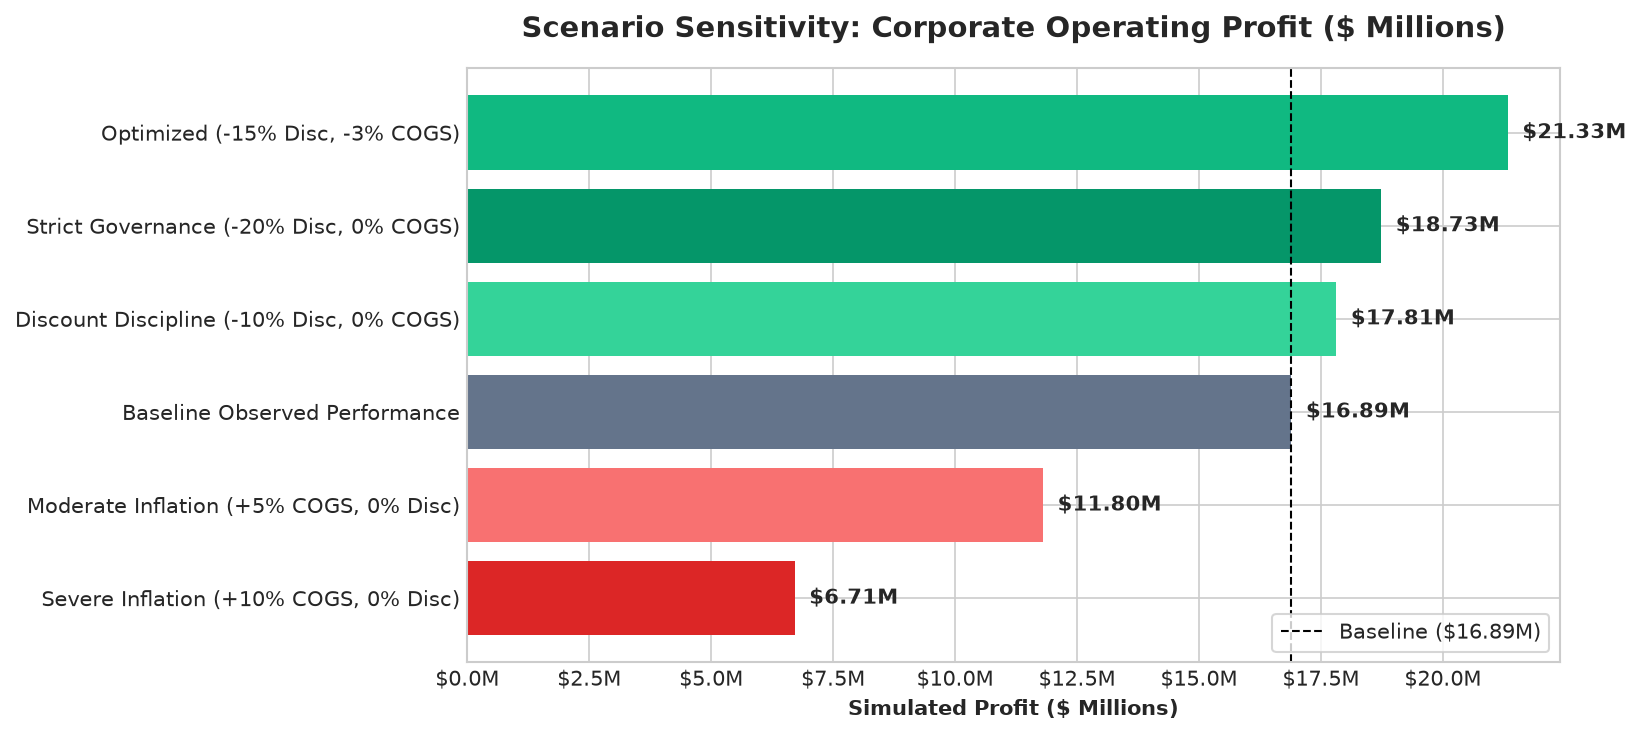

In [8]:
scenarios = [
    {"name": "Severe Inflation (+10% COGS, 0% Disc)", "disc": 0.0, "cogs": 0.10},
    {"name": "Moderate Inflation (+5% COGS, 0% Disc)", "disc": 0.0, "cogs": 0.05},
    {"name": "Baseline Observed Performance", "disc": 0.0, "cogs": 0.0},
    {"name": "Discount Discipline (-10% Disc, 0% COGS)", "disc": -0.10, "cogs": 0.0},
    {"name": "Strict Governance (-20% Disc, 0% COGS)", "disc": -0.20, "cogs": 0.0},
    {"name": "Optimized (-15% Disc, -3% COGS)", "disc": -0.15, "cogs": -0.03}
]

scenario_results = []
for s in scenarios:
    res = simulate_financial_scenario(df_fin, discount_pct_delta=s['disc'], cogs_pct_delta=s['cogs'])
    scenario_results.append({
        "Scenario Name": s['name'],
        "Sim Net Sales ($M)": f"${res['simulated']['net_sales']/1e6:.2f}M",
        "Sim Profit ($M)": f"${res['simulated']['total_profit']/1e6:.2f}M",
        "Profit Margin": f"{res['simulated']['gross_profit_margin_pct']:.2f}%",
        "Profit Variance ($M)": f"${res['variance']['profit_dollar_impact']/1e6:+.2f}M"
    })

scenario_table = pd.DataFrame(scenario_results)
print("--- Parameterized Financial Scenario Matrix ---")
print(scenario_table.to_string(index=False))

# Visualize Scenario Sensitivity
fig, ax = plt.subplots(figsize=(11, 5))
sim_profits = [simulate_financial_scenario(df_fin, s['disc'], s['cogs'])['simulated']['total_profit']/1e6 for s in scenarios]
labels = [s['name'] for s in scenarios]
colors = ['#DC2626', '#F87171', '#64748B', '#34D399', '#059669', '#10B981']

ax.barh(labels, sim_profits, color=colors)
ax.set_title('Scenario Sensitivity: Corporate Operating Profit ($ Millions)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Simulated Profit ($ Millions)', fontweight='bold')
ax.axvline(kpis['total_profit']/1e6, color='black', linestyle='--', linewidth=1, label=f"Baseline (${kpis['total_profit']/1e6:.2f}M)")
ax.xaxis.set_major_formatter('${x:,.1f}M')
ax.legend(loc='lower right', frameon=True)

for i, v in enumerate(sim_profits):
    ax.text(v + 0.3, i, f"${v:.2f}M", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig(fig_dir / "05_discount_scenario_sensitivity_matrix.png", dpi=300)
plt.show()

## 8. Executive Financial Findings & C-Suite Guidance

1. **Enterprise Segment Loss Leader Contagion**:
   - *Evidence*: The Enterprise segment generated \$20,749,145 in net sales, but generated a **-\$614,545.62 net loss** ($-2.96\%$ margin), with a staggering COGS ratio of $102.96\%$.
   - *Guidance*: Immediately moratorium large-scale enterprise discounting; reprice enterprise contracts to cover standard factory COGS.

2. **Government Segment Drives Over 67% of Portfolio Profit**:
   - *Evidence*: Government delivered \$52,504,260 in net sales and **\$11,388,173 in net profit** ($21.69\%$ margin), accounting for $67.4\%$ of total corporate profit.
   - *Guidance*: Protect and expand federal and municipal government channel partnerships; assign dedicated key account executives.

3. **High COGS Absorption Vulnerability**:
   - *Evidence*: Overall corporate COGS ratio stands at **$85.77\%$** of net sales. Even a $5\%$ increase in manufacturing or supply chain costs erodes \$5.09M ($30.1\%$) of net operating profit.
   - *Guidance*: Institute hedging on raw manufacturing materials and secure fixed 18-month supplier master service agreements.

4. **Product Line Leadership (Paseo vs. Carretera)**:
   - *Evidence*: `Paseo` is the leading revenue and profit driver (\$33.01M sales, \$4.79M profit), followed by `VTT` (\$3.03M profit). Conversely, `Carretera` yields only \$1.82M profit despite \$13.81M sales ($13.2\%$ margin).
   - *Guidance*: Reallocate assembly line production capacity from Carretera toward high-velocity Paseo and VTT runs.